# UX Analysis and Improvement of a College Student Portal

### Done by Kundan Mummaneni 23WU0102101  
## Human Computer Interaction & UX Engineering

This project analyzes student interaction with a college portal and uses
UX principles to identify usability problems and propose an improved
student dashboard.

The project includes user behavior analysis, visualization, UX scoring,
user segmentation, pain-point identification and a prototype dashboard.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

np.random.seed(42)

# Create simulated student user research data
n = 100

df = pd.DataFrame({
    "Student_ID": range(1, n + 1),
    "Login_Frequency": np.random.randint(2, 15, n),
    "Avg_Task_Time": np.random.normal(4.5, 1.5, n).clip(1, 10),
    "Navigation_Steps": np.random.randint(2, 10, n),
    "Errors_Per_Session": np.random.poisson(2, n),
    "Satisfaction": np.random.randint(1, 6, n),
    "Attendance_Usage": np.random.randint(1, 10, n),
    "Timetable_Usage": np.random.randint(1, 8, n),
    "Grades_Usage": np.random.randint(1, 7, n),
    "Exam_Usage": np.random.randint(1, 6, n),
    "Mobile_Usage": np.random.randint(30, 100, n)
})

# User type
df["User_Type"] = pd.cut(
    df["Login_Frequency"],
    bins=[0, 4, 9, 20],
    labels=["Occasional User", "Regular User", "Frequent User"]
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (100, 12)


,Student_ID,Login_Frequency,Avg_Task_Time,Navigation_Steps,Errors_Per_Session,Satisfaction,Attendance_Usage,Timetable_Usage,Grades_Usage,Exam_Usage,Mobile_Usage,User_Type
0,1,8,4.644625,4,2,2,8,7,5,5,37,Regular User
1,2,5,5.128653,5,2,3,4,6,2,1,63,Regular User
2,3,14,3.070458,2,3,5,8,6,1,3,64,Frequent User
3,4,12,2.928194,2,2,5,9,1,2,1,61,Frequent User
4,5,9,1.686485,3,4,1,3,6,6,5,75,Regular User


## 1. User Research and Basic Analysis

The dataset represents 100 simulated student users. The variables describe
login frequency, task completion time, navigation steps, errors,
satisfaction and usage of different portal features.

The data is used only for demonstrating the UX analysis process.

In [2]:
# Basic statistics
print("Average login frequency:",
      round(df["Login_Frequency"].mean(), 2))

print("Average task completion time:",
      round(df["Avg_Task_Time"].mean(), 2), "minutes")

print("Average navigation steps:",
      round(df["Navigation_Steps"].mean(), 2))

print("Average errors per session:",
      round(df["Errors_Per_Session"].mean(), 2))

print("Average satisfaction:",
      round(df["Satisfaction"].mean(), 2), "/ 5")


# Frequently used features
feature_usage = pd.DataFrame({
    "Feature": ["Attendance", "Timetable", "Grades", "Examinations"],
    "Usage": [
        df["Attendance_Usage"].sum(),
        df["Timetable_Usage"].sum(),
        df["Grades_Usage"].sum(),
        df["Exam_Usage"].sum()
    ]
}).sort_values("Usage", ascending=False)

print("\nFeature Usage:")
display(feature_usage)

Average login frequency: 8.27
Average task completion time: 4.52 minutes
Average navigation steps: 5.63
Average errors per session: 1.83
Average satisfaction: 2.88 / 5

Feature Usage:


,Feature,Usage
0,Attendance,522
1,Timetable,396
2,Grades,360
3,Examinations,277


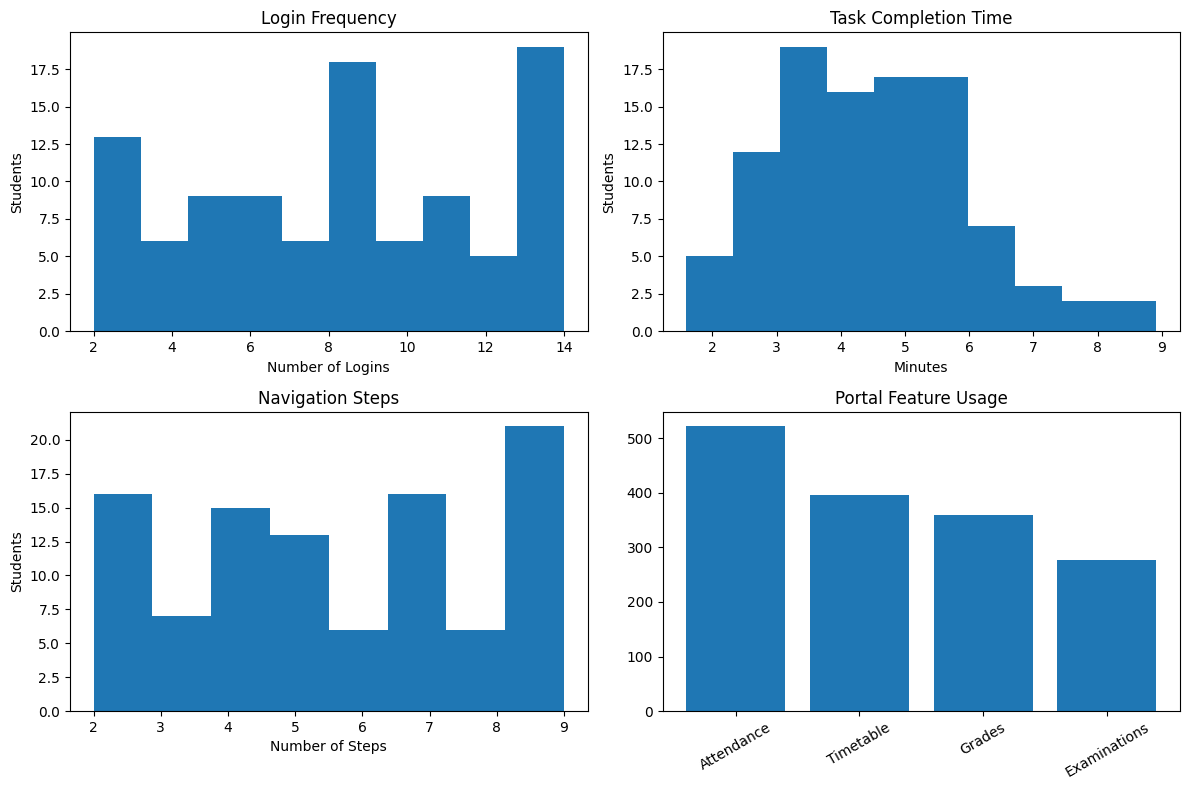

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Login frequency
axes[0,0].hist(df["Login_Frequency"], bins=10)
axes[0,0].set_title("Login Frequency")
axes[0,0].set_xlabel("Number of Logins")
axes[0,0].set_ylabel("Students")

# Task completion time
axes[0,1].hist(df["Avg_Task_Time"], bins=10)
axes[0,1].set_title("Task Completion Time")
axes[0,1].set_xlabel("Minutes")
axes[0,1].set_ylabel("Students")

# Navigation steps
axes[1,0].hist(df["Navigation_Steps"], bins=8)
axes[1,0].set_title("Navigation Steps")
axes[1,0].set_xlabel("Number of Steps")
axes[1,0].set_ylabel("Students")

# Feature usage
axes[1,1].bar(
    feature_usage["Feature"],
    feature_usage["Usage"]
)
axes[1,1].set_title("Portal Feature Usage")
axes[1,1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 2. UX Score

A UX score is calculated using satisfaction, task completion time,
navigation complexity and errors.

Higher satisfaction improves the score, while longer task time,
more navigation steps and more errors reduce it.

Average UX Score: 54.49
Highest UX Score: 93.68
Lowest UX Score: 15.72


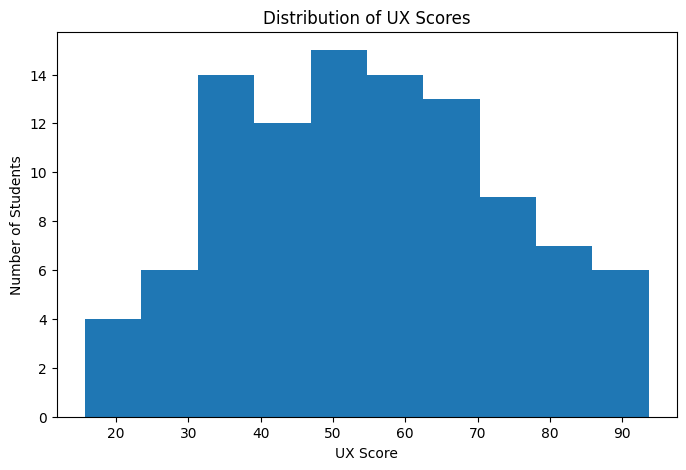

In [6]:
# Normalize variables
def normalize(series):
    return (series - series.min()) / (series.max() - series.min())

df["Satisfaction_N"] = normalize(df["Satisfaction"])
df["Time_N"] = normalize(df["Avg_Task_Time"])
df["Navigation_N"] = normalize(df["Navigation_Steps"])
df["Errors_N"] = normalize(df["Errors_Per_Session"])

# Calculate UX score
df["UX_Score"] = (
    0.40 * df["Satisfaction_N"] +
    0.25 * (1 - df["Time_N"]) +
    0.20 * (1 - df["Navigation_N"]) +
    0.15 * (1 - df["Errors_N"])
) * 100

print("Average UX Score:", round(df["UX_Score"].mean(), 2))
print("Highest UX Score:", round(df["UX_Score"].max(), 2))
print("Lowest UX Score:", round(df["UX_Score"].min(), 2))

plt.figure(figsize=(8,5))
plt.hist(df["UX_Score"], bins=10)
plt.title("Distribution of UX Scores")
plt.xlabel("UX Score")
plt.ylabel("Number of Students")
plt.show()

## 3. Relationship Between UX Variables

Correlation analysis is used to understand how different user behavior
variables are related. Navigation complexity, task completion time,
errors and satisfaction are particularly important UX indicators.

,Login_Frequency,Avg_Task_Time,Navigation_Steps,Errors_Per_Session,Satisfaction,UX_Score
Login_Frequency,1.000000,-0.062434,0.046031,-0.162249,-0.054591,-0.017580
Avg_Task_Time,-0.062434,1.000000,0.110546,0.053091,-0.045421,-0.367161
Navigation_Steps,0.046031,0.110546,1.000000,0.123404,-0.081939,-0.499782
Errors_Per_Session,-0.162249,0.053091,0.123404,1.000000,-0.010202,-0.230603
Satisfaction,-0.054591,-0.045421,-0.081939,-0.010202,1.000000,0.840744
UX_Score,-0.017580,-0.367161,-0.499782,-0.230603,0.840744,1.000000


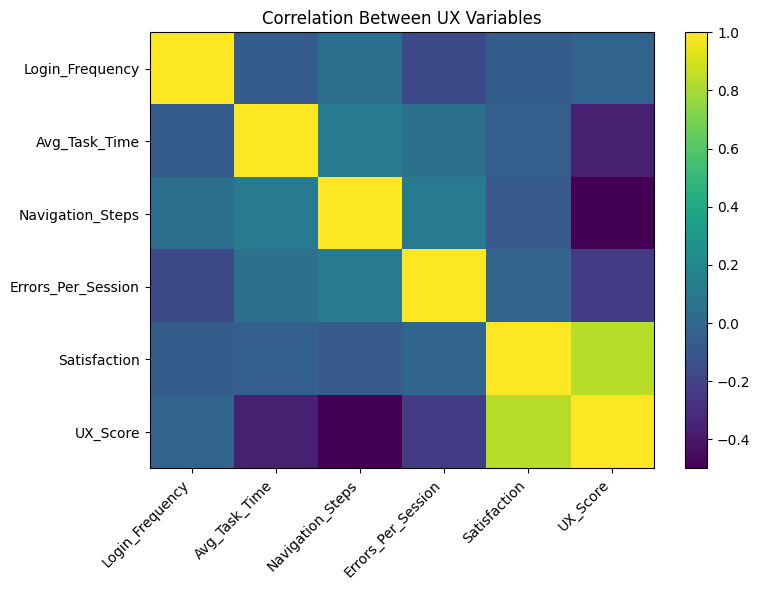

In [7]:
corr_columns = [
    "Login_Frequency",
    "Avg_Task_Time",
    "Navigation_Steps",
    "Errors_Per_Session",
    "Satisfaction",
    "UX_Score"
]

correlation = df[corr_columns].corr()

display(correlation)

plt.figure(figsize=(8,6))
plt.imshow(correlation, aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Between UX Variables")
plt.tight_layout()
plt.show()

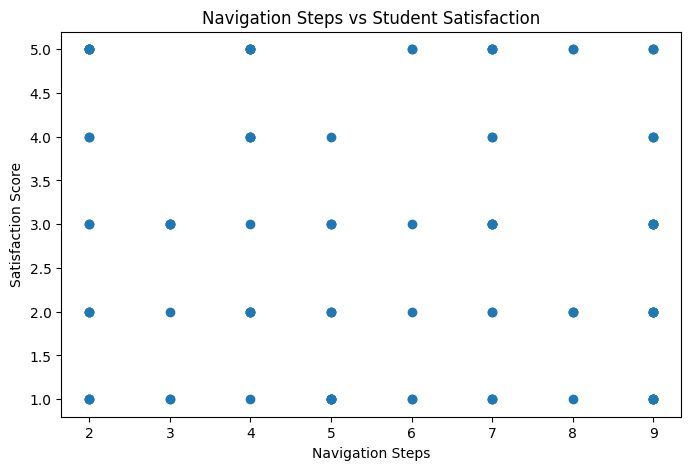

In [9]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["Navigation_Steps"],
    df["Satisfaction"]
)

plt.title("Navigation Steps vs Student Satisfaction")
plt.xlabel("Navigation Steps")
plt.ylabel("Satisfaction Score")

plt.show()

## 4. User Segmentation

Students have different patterns of portal usage. K-Means clustering is
used to group students according to login frequency, task time,
navigation steps, errors and satisfaction.

,Login_Frequency,Avg_Task_Time,Navigation_Steps,Errors_Per_Session,Satisfaction
Cluster,,,,,
0,7.263158,4.506982,5.236842,1.657895,4.394737
1,9.714286,4.100044,4.200000,1.200000,1.857143
2,7.814815,5.097796,8.037037,2.888889,2.074074


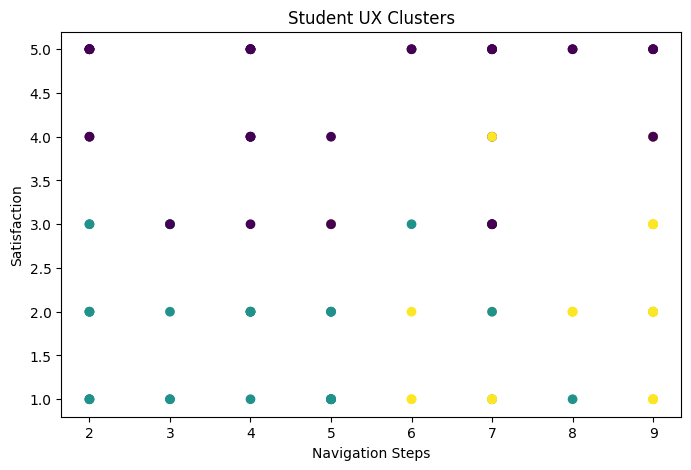

In [10]:
features = [
    "Login_Frequency",
    "Avg_Task_Time",
    "Navigation_Steps",
    "Errors_Per_Session",
    "Satisfaction"
]

X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

cluster_summary = df.groupby("Cluster")[features].mean()

display(cluster_summary)

plt.figure(figsize=(8,5))

plt.scatter(
    df["Navigation_Steps"],
    df["Satisfaction"],
    c=df["Cluster"]
)

plt.title("Student UX Clusters")
plt.xlabel("Navigation Steps")
plt.ylabel("Satisfaction")

plt.show()

## 5. UX Pain-Point Identification

Users with high navigation steps, longer task completion time and low
satisfaction are considered potential UX pain-point users.

The results are used to identify areas where the portal can be improved.

Users with major UX pain points: 13
Percentage of users: 13.0 %


,Problem,Priority
0,Too many navigation steps,5
1,Long task completion time,5
2,Low satisfaction,5
3,Frequent attendance access,4
4,Frequent timetable access,4
5,Navigation errors,4


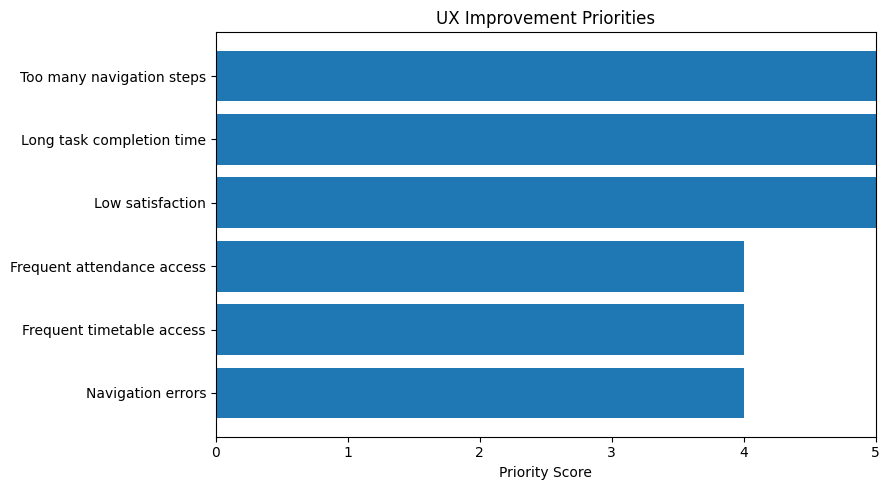

In [11]:
# Identify users experiencing major UX problems
pain_points = df[
    (df["Navigation_Steps"] >= 7) &
    (df["Avg_Task_Time"] >= 5) &
    (df["Satisfaction"] <= 3)
]

print("Users with major UX pain points:", len(pain_points))
print(
    "Percentage of users:",
    round(len(pain_points) / len(df) * 100, 2),
    "%"
)

# Priority of UX improvements
improvements = pd.DataFrame({
    "Problem": [
        "Too many navigation steps",
        "Long task completion time",
        "Low satisfaction",
        "Frequent attendance access",
        "Frequent timetable access",
        "Navigation errors"
    ],
    "Priority": [5, 5, 5, 4, 4, 4]
})

display(improvements)

plt.figure(figsize=(9,5))
plt.barh(
    improvements["Problem"],
    improvements["Priority"]
)

plt.title("UX Improvement Priorities")
plt.xlabel("Priority Score")
plt.xlim(0,5)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## 6. Proposed UX Solution

Based on the analysis, the redesigned student portal should reduce
unnecessary navigation and provide direct access to frequently used
features.

The main dashboard will contain:

- Attendance
- Today's Timetable
- Grades
- Examination Information
- Announcements
- Documents

The interface should use clear labels, consistent navigation, readable
text and sufficient colour contrast. This follows the HCI principles of
usability, user-centered design and accessibility.

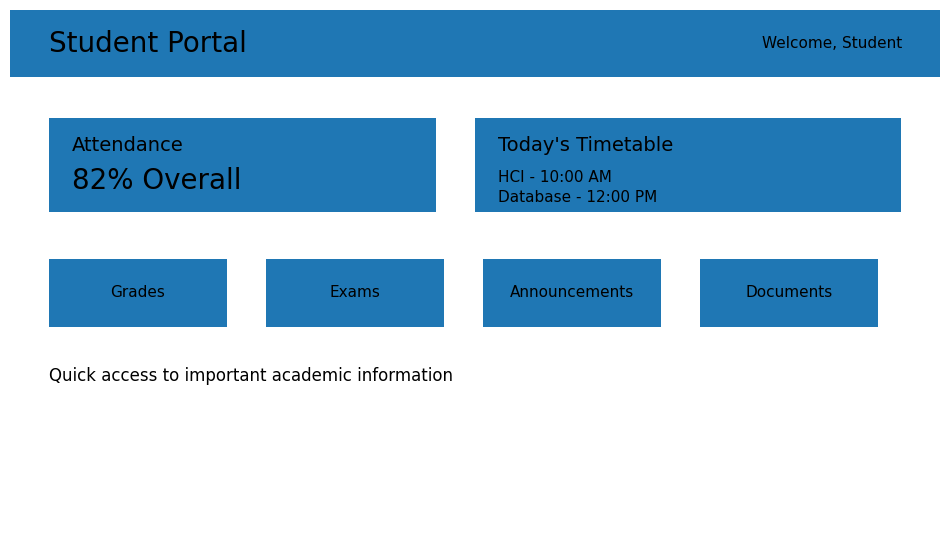

In [12]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(12,7))

ax.set_xlim(0,12)
ax.set_ylim(0,8)
ax.axis("off")

# Header
ax.add_patch(Rectangle((0,7), 12,1))

ax.text(
    0.5, 7.5,
    "Student Portal",
    fontsize=20,
    va="center"
)

ax.text(
    9.7, 7.5,
    "Welcome, Student",
    fontsize=11,
    va="center"
)

# Attendance
ax.add_patch(Rectangle((0.5,5), 5,1.4))

ax.text(0.8,5.9,"Attendance",fontsize=14)
ax.text(0.8,5.35,"82% Overall",fontsize=20)

# Timetable
ax.add_patch(Rectangle((6,5),5.5,1.4))

ax.text(6.3,5.9,"Today's Timetable",fontsize=14)
ax.text(6.3,5.45,"HCI - 10:00 AM",fontsize=11)
ax.text(6.3,5.15,"Database - 12:00 PM",fontsize=11)

# Quick access
buttons = [
    ("Grades",0.5,3.3),
    ("Exams",3.3,3.3),
    ("Announcements",6.1,3.3),
    ("Documents",8.9,3.3)
]

for label,x,y in buttons:
    ax.add_patch(Rectangle((x,y),2.3,1))
    ax.text(
        x+1.15,
        y+0.5,
        label,
        ha="center",
        va="center",
        fontsize=11
    )

ax.text(
    0.5,2.5,
    "Quick access to important academic information",
    fontsize=12
)

plt.show()

## 7. Usability Evaluation

The proposed design is evaluated using five usability characteristics:
learnability, efficiency, memorability, error prevention and satisfaction.

The scores represent an initial evaluation of the proposed design.
Actual user testing can be performed in future work.

,Criterion,Score
0,Learnability,4
1,Efficiency,5
2,Memorability,4
3,Error Prevention,4
4,Satisfaction,4


Overall Usability Score: 4.20/5


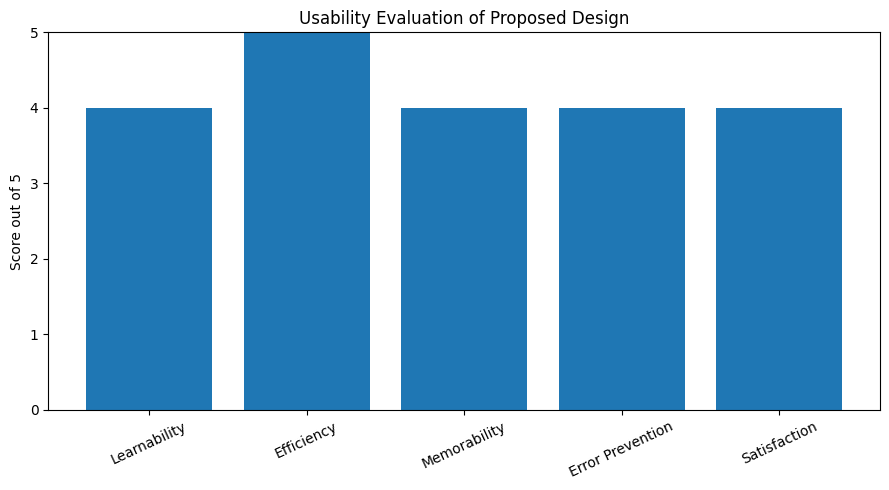

In [13]:
usability = pd.DataFrame({
    "Criterion": [
        "Learnability",
        "Efficiency",
        "Memorability",
        "Error Prevention",
        "Satisfaction"
    ],
    "Score": [4,5,4,4,4]
})

display(usability)

overall_score = usability["Score"].mean()

print(
    f"Overall Usability Score: {overall_score:.2f}/5"
)

plt.figure(figsize=(9,5))

plt.bar(
    usability["Criterion"],
    usability["Score"]
)

plt.title("Usability Evaluation of Proposed Design")
plt.ylabel("Score out of 5")
plt.ylim(0,5)

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# 8. Results and Discussion

The analysis shows that students frequently access attendance, timetable,
grades and examination information. Navigation complexity, task
completion time and satisfaction are important factors affecting the
overall UX.

The user segmentation demonstrates that students have different usage
patterns. The pain-point analysis identifies users who may experience
difficulty due to excessive navigation, longer task times and lower
satisfaction.

Based on these findings, the proposed dashboard provides direct access
to frequently used information and reduces unnecessary navigation.

The prototype also considers usability and accessibility through clear
labels, simple navigation and readable interface elements.

# 9. Conclusion

This project applied HCI and UX principles to analyze and improve a
college student portal. Python was used for data generation, analysis,
visualization, UX scoring and user segmentation.

The analysis was then used to identify UX problems and design a simpler
student dashboard. The proposed solution focuses on usability,
efficiency, accessibility and user-centered design.

The project demonstrates how user behavior data can support UX design
decisions and help create more effective digital interfaces.